# 02. Etapa I: algoritmos clássicos

SVM e MLP, com Random Forest e XGBoost como referência. Busca em grade com validação cruzada estratificada de 5 folds, otimizando F1. O código está em `src/train_classical.py`.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # comandos python -m src.* rodam a partir da raiz
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from src import config as C
pd.set_option("display.max_columns", 30)

## 1. Treinamento

A grade completa leva alguns minutos. Para conferir o pipeline rapidamente, use `--quick`.

In [2]:
# teste rápido do pipeline (grade mínima, fora do summary.csv)
# !"{sys.executable}" -m src.train_classical --quick

In [3]:
# grade completa (configuração principal: SMOTE)
!"{sys.executable}" -m src.train_classical


[svm] melhor F1 (CV) = 0.542  params = {'clf__C': 100, 'clf__gamma': 'scale'}  (187s)
   test_full   acc=0.953 prec=0.402 rec=0.779 f1=0.530 auc=0.9508
   eval_sample acc=0.940 prec=0.975 rec=0.780 f1=0.867 auc=0.9641

[mlp] melhor F1 (CV) = 0.594  params = {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.01}  (81s)
   test_full   acc=0.967 prec=0.509 rec=0.809 f1=0.625 auc=0.969
   eval_sample acc=0.945 prec=0.976 rec=0.800 f1=0.879 auc=0.9788

[rf] melhor F1 (CV) = 0.631  params = {'clf__max_depth': None, 'clf__n_estimators': 200}  (19s)
   test_full   acc=0.966 prec=0.495 rec=0.735 f1=0.592 auc=0.9726
   eval_sample acc=0.920 prec=0.947 rec=0.720 f1=0.818 auc=0.9791

[xgb] melhor F1 (CV) = 0.689  params = {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 500}  (8s)
   test_full   acc=0.983 prec=0.714 rec=0.809 f1=0.759 auc=0.9697
   eval_sample acc=0.945 prec=0.976 rec=0.800 f1=0.879 auc=0.9729

Resumo salvo em reports\resul

In [4]:
# variações: pesos de classe no lugar do SMOTE e atributos derivados
!"{sys.executable}" -m src.train_classical --balance class_weight
!"{sys.executable}" -m src.train_classical --engineered


[svm] melhor F1 (CV) = 0.537  params = {'clf__C': 100, 'clf__gamma': 'scale'}  (14s)
   test_full   acc=0.950 prec=0.374 rec=0.721 f1=0.492 auc=0.9549
   eval_sample acc=0.915 prec=0.923 rec=0.720 f1=0.809 auc=0.9715

[mlp] melhor F1 (CV) = 0.640  params = {'clf__alpha': 0.001, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.01}  (10s)
   test_full   acc=0.979 prec=0.861 rec=0.456 f1=0.596 auc=0.9738
   eval_sample acc=0.845 prec=1.000 rec=0.380 f1=0.551 auc=0.9893

[rf] melhor F1 (CV) = 0.678  params = {'clf__max_depth': 20, 'clf__n_estimators': 500}  (10s)
   test_full   acc=0.980 prec=0.726 rec=0.662 f1=0.692 auc=0.9636
   eval_sample acc=0.910 prec=1.000 rec=0.640 f1=0.780 auc=0.9752

[xgb] melhor F1 (CV) = 0.744  params = {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 500}  (7s)
   test_full   acc=0.984 prec=0.757 rec=0.779 f1=0.768 auc=0.9701
   eval_sample acc=0.945 prec=1.000 rec=0.780 f1=0.876 auc=0.9696

Resumo salvo em reports\result


[svm] melhor F1 (CV) = 0.605  params = {'clf__C': 100, 'clf__gamma': 0.1}  (155s)
   test_full   acc=0.961 prec=0.451 rec=0.735 f1=0.559 auc=0.9582
   eval_sample acc=0.915 prec=0.946 rec=0.700 f1=0.805 auc=0.9689

[mlp] melhor F1 (CV) = 0.640  params = {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (64, 32), 'clf__learning_rate_init': 0.01}  (304s)
   test_full   acc=0.968 prec=0.518 rec=0.838 f1=0.640 auc=0.9709
   eval_sample acc=0.950 prec=0.955 rec=0.840 f1=0.894 auc=0.9791

[rf] melhor F1 (CV) = 0.760  params = {'clf__max_depth': None, 'clf__n_estimators': 200}  (173s)
   test_full   acc=0.978 prec=0.636 rec=0.824 f1=0.718 auc=0.9692
   eval_sample acc=0.945 prec=0.954 rec=0.820 f1=0.882 auc=0.9757

[xgb] melhor F1 (CV) = 0.794  params = {'clf__learning_rate': 0.1, 'clf__max_depth': 6, 'clf__n_estimators': 500}  (74s)
   test_full   acc=0.982 prec=0.696 rec=0.809 f1=0.748 auc=0.9849
   eval_sample acc=0.945 prec=0.976 rec=0.800 f1=0.879 auc=0.9879

Resumo salvo em reports\resul

## 2. Resultados

In [5]:
res = pd.read_csv(C.RESULTS / 'summary.csv')
metricas = ['model', 'setting', 'eval_set', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'cv_f1', 'best_params']
res[res['stage'] == 'I'][metricas].sort_values(['eval_set', 'f1'], ascending=[False, False])

,model,setting,eval_set,accuracy,precision,recall,f1,roc_auc,cv_f1,best_params
24,xgb,balance=class_weight,test_full,0.9840,0.7571,0.7794,0.7681,0.9701,0.7439,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ..."
16,xgb,balance=smote,test_full,0.9825,0.7143,0.8088,0.7586,0.9697,0.6891,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ..."
32,xgb,"balance=smote,engineered",test_full,0.9815,0.6962,0.8088,0.7483,0.9849,0.7941,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ..."
30,rf,"balance=smote,engineered",test_full,0.9780,0.6364,0.8235,0.7179,0.9692,0.7600,"{""clf__max_depth"": null, ""clf__n_estimators"": ..."
22,rf,balance=class_weight,test_full,0.9800,0.7258,0.6618,0.6923,0.9636,0.6785,"{""clf__max_depth"": 20, ""clf__n_estimators"": 500}"
28,mlp,"balance=smote,engineered",test_full,0.9680,0.5182,0.8382,0.6404,0.9709,0.6405,"{""clf__alpha"": 0.01, ""clf__hidden_layer_sizes""..."
12,mlp,balance=smote,test_full,0.9670,0.5093,0.8088,0.6250,0.9690,0.5936,"{""clf__alpha"": 0.01, ""clf__hidden_layer_sizes""..."
20,mlp,balance=class_weight,test_full,0.9790,0.8611,0.4559,0.5962,0.9738,0.6405,"{""clf__alpha"": 0.001, ""clf__hidden_layer_sizes..."
14,rf,balance=smote,test_full,0.9655,0.4950,0.7353,0.5917,0.9726,0.6308,"{""clf__max_depth"": null, ""clf__n_estimators"": ..."
26,svm,"balance=smote,engineered",test_full,0.9605,0.4505,0.7353,0.5587,0.9582,0.6053,"{""clf__C"": 100, ""clf__gamma"": 0.1}"


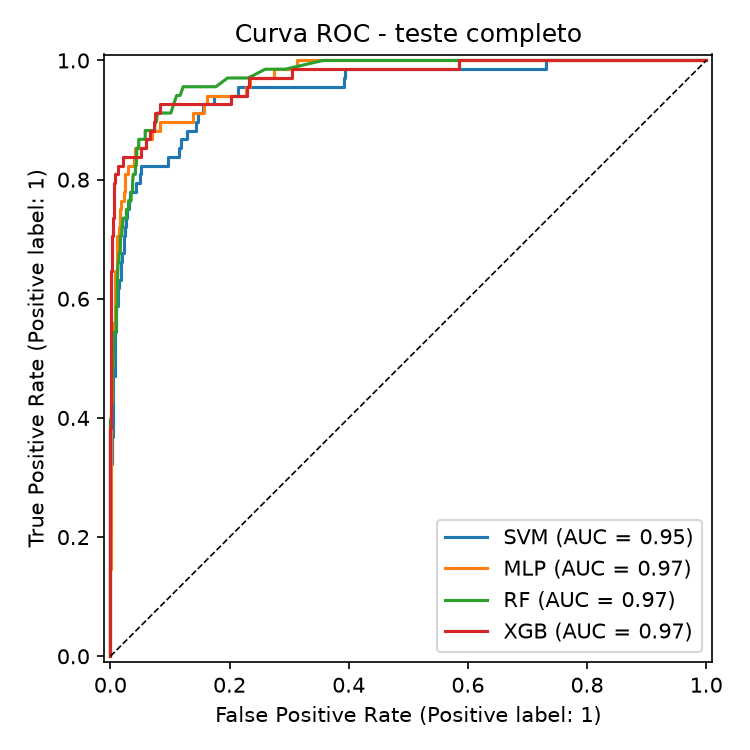

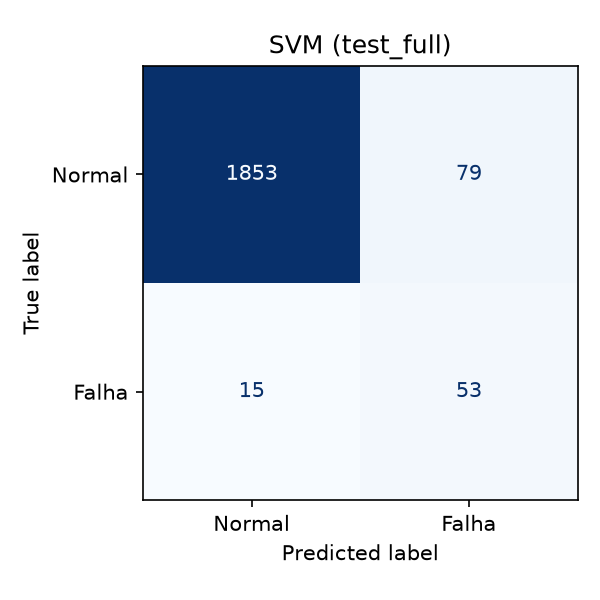

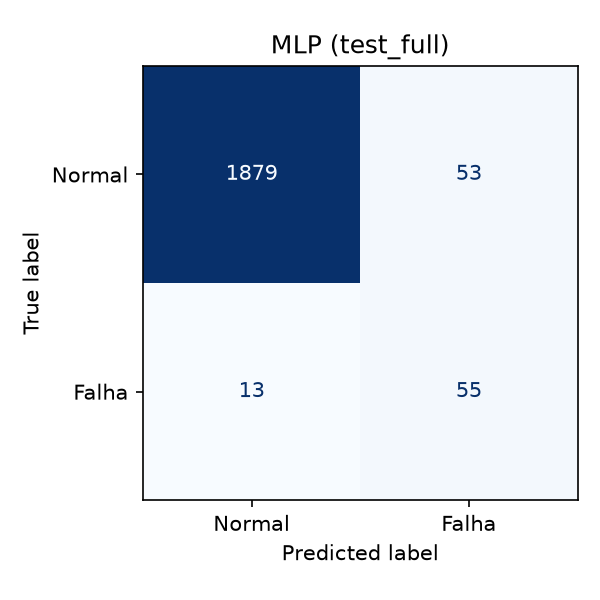

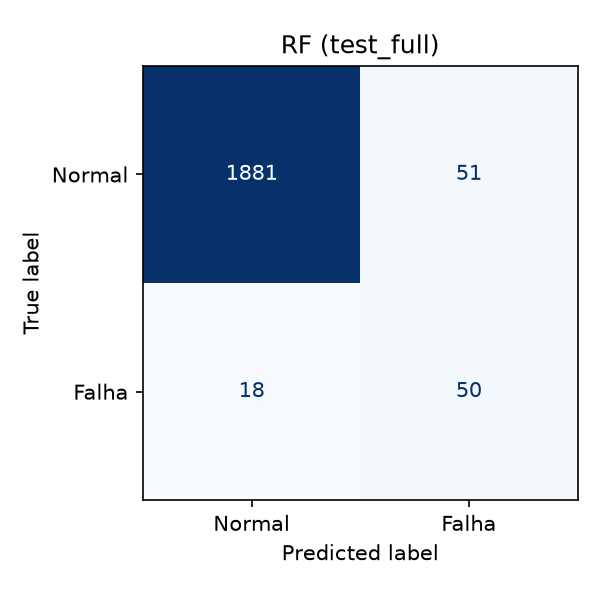

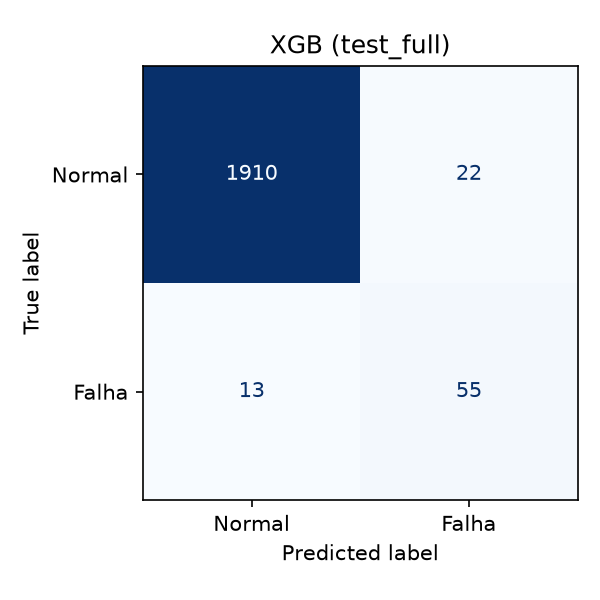

In [6]:
display(Image(C.FIGURES / 'roc_classical.png'))
for m in ['svm', 'mlp', 'rf', 'xgb']:
    p = C.FIGURES / f'cm_{m}_test_full.png'
    if p.exists():
        display(Image(p, width=300))